# Proyecto No. 1 — Clasificación de autores
### Bag of Words con unigramas

**Materia:** Métodos de Texto (NLP) &nbsp;|&nbsp; **Proyecto No. 1: Text Classification**

**Equipo 3**
*Lambda Remiel Heredia Pérez y Diego Octavio Pérez Urbina*

---

Este cuaderno identifica al autor de una obra entre cuatro escritores.
El material se recorre de principio a fin en la presentación frente al grupo.

**Contenido**

1. Objetivo
2. Corpus y ligas a los acervos
3. Preparación de los archivos
4. Carga y partición entrenamiento / prueba
5. Preprocesamiento
6. Diccionario de las 300 palabras más frecuentes
7. Clasificadores
8. Resultados con el diccionario de todos los textos
9. Comparación: diccionario calculado solo con el entrenamiento
10. Palabras que separan a los autores
11. Guion breve para la presentación


## 1. Objetivo

El sistema debe decir quién escribió cada parte del conjunto de prueba.
Los autores son:

- Jean-Paul Sartre
- Albert Camus
- Simone de Beauvoir
- Emil Cioran

Cada autor aporta **una sola obra**. El cuaderno la corta en **8 partes** con el mismo número de tokens.
La unidad de clasificación es esa **parte**, no la obra completa.
Las **3 últimas** partes de cada obra van a la prueba. Las primeras 5 entrenan el modelo.

La representación es una **bolsa de palabras (Bag of Words) de unigramas**.
El diccionario tiene las **300 palabras más frecuentes en todos los textos**.


## 2. Corpus y ligas a los acervos

No hay un dataset en dominio público con las obras completas de los cuatro autores.
Estas son las ligas que consultamos:

- Albert Camus, obras en francés: [Les Classiques des sciences sociales (UQAM)](https://www.classiques.uqam.ca/classiques/camus_albert/camus_albert.html).
  Esa biblioteca indica que aplica la regla canadiense de dominio público y pide respetar la ley del país de quien descarga.
- Jean-Paul Sartre, ensayos y fragmentos, sobre todo en inglés: [Marxists Internet Archive](https://www.marxists.org/reference/archive/sartre/).
  No es un conjunto de obras completas en francés.
- Simone de Beauvoir, *The Ethics of Ambiguity* y partes de *The Second Sex*, en inglés: [marxists.org](https://www.marxists.org/reference/subject/ethics/de-beauvoir/ambiguity/).
- Emil Cioran, ficha de catálogo de *Précis de décomposition*: [BnF](https://catalogue.bnf.fr/ark:/12148/cb16512908s).
  No encontramos un acervo abierto con sus obras completas en francés.

En México el derecho de autor dura la vida del autor y 100 años más.
Camus murió en 1960, Sartre en 1980, Beauvoir en 1986 y Cioran en 1995.
Sus libros siguen protegidos. Este cuaderno no contiene las obras.
Coloca en `data/` un archivo `.txt` por autor, tomado de una copia que tengas derecho a usar.
Los archivos de esa carpeta no se suben a git.

Todos los textos deben estar en **francés**.
Las palabras funcionales en francés son del autor.
Una traducción al español también lleva el estilo del traductor.
Los libros tempranos de Cioran en rumano quedan fuera: si no, el idioma lo identifica solo.

No incluyas *Les Possédés* de Camus. Es una adaptación de Dostoievski, y el estilo no es solo de Camus. Si ese archivo está en la carpeta, el cuaderno lo omite.


## 3. Preparación de los archivos

Abre este cuaderno desde la carpeta `Proyecto1`, o desde la raíz del repositorio.
Crea esta estructura. Un archivo `.txt` es una obra. Codificación UTF-8.

```text
data/
  sartre/
  camus/
  beauvoir/
  cioran/
```

Cada carpeta debe tener **un solo** archivo `.txt`: la obra de ese autor.
Si falta un autor o hay más de un `.txt`, el cuaderno se detiene y dice qué falta.

Ese archivo se corta en **8 partes** con el mismo número de tokens.
La obra más corta fija ese número, para que un libro largo no gane solo por ser largo.
Las partes se reparten desde el inicio hasta el final y no se solapan.
Las partes 1 a 5 son entrenamiento. Las partes 6 a 8 son la prueba.

Antes de cortar, el cuaderno quita texto que no es del autor:

- Sartre: el encabezado en español del seminario y las marcas de página.
- Camus: la línea «Amis de la Littérature Française» y el encabezado de página.
- Beauvoir: la préface de Benoîte Groult. El texto usado empieza en `INTRODUCTION`.
- Cioran: la portada, los agradecimientos y el índice. El texto usado empieza en `INTRODUCTION`.

El archivo de la carpeta `cioran` no es una obra de Cioran.
Es el mémoire *Émile-Michel Cioran: de l'absurde à l'absolu* (Bellajalbert, 1993).
El cuaderno lo carga para poder correr con estos archivos.
En la presentación hay que decirlo: esa clase aprende la prosa del mémoire, no la prosa de Cioran.

**Dependencias:** `numpy`, `pandas`, `scikit-learn`, `matplotlib`.


In [1]:
from __future__ import annotations

import os
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB

AUTHORS = {
    "sartre": "Jean-Paul Sartre",
    "camus": "Albert Camus",
    "beauvoir": "Simone de Beauvoir",
    "cioran": "Emil Cioran",
}

SOURCE_TITLES = {
    "sartre": "L'existentialisme est un humanisme",
    "camus": "Le Mythe de Sisyphe",
    "beauvoir": "Le Deuxième Sexe, I",
    "cioran": "De l'absurde à l'absolu",
}

SHORT_LABELS = {
    "Jean-Paul Sartre": "Sartre",
    "Albert Camus": "Camus",
    "Simone de Beauvoir": "Beauvoir",
    "Emil Cioran": "Cioran",
}

TOKEN_RE = re.compile(r"[a-zàâäéèêëïîôùûüçœæ]+")
VOCAB_SIZE = 300
N_PARTS = 8
N_TEST = 3
LABELS = list(AUTHORS.values())


## 4. Carga y partición

Cada carpeta tiene un `.txt`. Ese archivo es una obra.
El cuaderno lo limpia y lo corta en 8 partes del mismo largo.
La partición no es aleatoria: las partes 1 a 5 van a **entrenamiento** y las partes 6 a 8 van a **prueba**.
Así el resultado se puede explicar parte por parte en la presentación.


In [2]:
def find_data_dir() -> Path:
    # CLASIFICACION_DATA permite apuntar a otra carpeta sin mover el cuaderno.
    if os.environ.get("CLASIFICACION_DATA"):
        return Path(os.environ["CLASIFICACION_DATA"]).expanduser().resolve()
    here = Path.cwd().resolve()
    candidates = [here / "data", here / "Proyecto1" / "data", here.parent / "data"]
    for path in candidates:
        if path.is_dir():
            return path
    return here / "data"


def normalize_key(name: str) -> str:
    decomposed = unicodedata.normalize("NFKD", name)
    without_marks = "".join(char for char in decomposed if not unicodedata.combining(char))
    return re.sub(r"[^a-z0-9]+", "", without_marks.lower())


def tokenize(text: str) -> list[str]:
    normalized = unicodedata.normalize("NFKC", text).lower()
    return TOKEN_RE.findall(normalized)


def _join_pdf_hyphens(text: str) -> str:
    text = text.replace("\u00ad", "")
    return re.sub(r"-\s*\n\s*", "", text)


def _cut_from_marker(text: str, marker: str) -> str:
    lines = text.splitlines()
    for index, line in enumerate(lines):
        if line.strip() == marker:
            return "\n".join(lines[index:])
    return text


def clean_source(author_key: str, text: str) -> str:
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    if author_key == "sartre":
        kept: list[str] = []
        for line in text.splitlines():
            stripped = line.strip()
            low = stripped.lower()
            if low.startswith("facultad de filosofía") or low.startswith("facultad de filosofia"):
                continue
            if low.startswith("seminario de profesores"):
                continue
            if low.startswith("las cuestiones metafísica") or low.startswith("las cuestiones metafisica"):
                continue
            if low.startswith("en el existencialismo de j"):
                continue
            if re.fullmatch(r"-\s*\d+\s*-", stripped):
                continue
            kept.append(line)
        text = "\n".join(kept)
        text = re.sub(r"\[\d+\]", " ", text)
    elif author_key == "camus":
        kept = []
        for line in text.splitlines():
            stripped = line.strip()
            if "Amis de la Littérature Française" in stripped:
                continue
            if "LE MYTHE DE SISYPHE" in stripped and "CAMUS" in stripped:
                continue
            kept.append(line)
        text = "\n".join(kept)
    elif author_key in {"beauvoir", "cioran"}:
        text = _cut_from_marker(text, "INTRODUCTION")
    return _join_pdf_hyphens(text)


def spread_parts(tokens: list[str], n_parts: int, part_size: int) -> list[list[str]]:
    last_start = len(tokens) - part_size
    starts = [round(i * last_start / (n_parts - 1)) for i in range(n_parts)]
    return [tokens[start : start + part_size] for start in starts]


def read_works(data_dir: Path) -> list[dict]:
    if not data_dir.is_dir():
        raise FileNotFoundError(
            f"No existe la carpeta de textos: {data_dir}. "
            "Crea data/sartre, data/camus, data/beauvoir y data/cioran, con un archivo .txt por autor."
        )

    problems: list[str] = []
    loaded: list[tuple[str, Path, list[str]]] = []

    for author_key, author_name in AUTHORS.items():
        folder = data_dir / author_key
        files = sorted(path for path in folder.glob("*.txt")) if folder.is_dir() else []
        if author_key == "camus":
            kept = []
            for path in files:
                if "possedes" in normalize_key(path.stem):
                    print(f"Se omite {path.name}: es una adaptación de Dostoievski, no solo de Camus.")
                else:
                    kept.append(path)
            files = kept
        if len(files) != 1:
            problems.append(
                f"{author_name}: hay {len(files)} archivo(s) .txt en {folder}. Se necesita exactamente 1."
            )
            continue

        path = files[0]
        tokens = tokenize(clean_source(author_key, path.read_text(encoding="utf-8")))
        if len(tokens) < N_PARTS:
            problems.append(
                f"{author_name}: {path.name} no tiene tokens suficientes para {N_PARTS} partes."
            )
            continue
        if author_key == "cioran":
            print(
                "Aviso: data/cioran no contiene una obra de Cioran. "
                "El archivo es el mémoire «Émile-Michel Cioran: de l'absurde à l'absolu» "
                "(Bellajalbert, 1993). El modelo verá esa prosa, no la de Cioran."
            )
        loaded.append((author_key, path, tokens))

    if problems:
        detail = "\n".join(f"- {line}" for line in problems)
        raise FileNotFoundError(
            "El corpus no está completo. Cada autor necesita un solo archivo .txt.\n" + detail
        )

    shortest = min(len(tokens) for _key, _path, tokens in loaded)
    part_size = shortest // N_PARTS
    n_train = N_PARTS - N_TEST
    print(
        f"Cada obra se corta en {N_PARTS} partes de {part_size} tokens. "
        f"Partes 1–{n_train}: entrenamiento. Partes {n_train + 1}–{N_PARTS}: prueba."
    )
    print(f"El largo lo fija la obra más corta ({shortest} tokens).")

    works: list[dict] = []
    for author_key, path, tokens in loaded:
        title = SOURCE_TITLES[author_key]
        for index, part in enumerate(spread_parts(tokens, N_PARTS, part_size), start=1):
            split = "entrenamiento" if index <= n_train else "prueba"
            works.append(
                {
                    "autor_id": author_key,
                    "autor": AUTHORS[author_key],
                    "titulo": f"{title} — parte {index}",
                    "archivo": path.name,
                    "particion": split,
                    "tokens": part,
                }
            )
    return works


data_dir = find_data_dir()
print(f"Carpeta de textos: {data_dir}")
works = read_works(data_dir)

corpus = pd.DataFrame(
    [
        {
            "autor": work["autor"],
            "parte": work["titulo"],
            "partición": work["particion"],
            "archivo": work["archivo"],
            "tokens": len(work["tokens"]),
        }
        for work in works
    ]
)
author_order = {name: index for index, name in enumerate(LABELS)}
corpus["_autor"] = corpus["autor"].map(author_order)
corpus["_particion"] = corpus["partición"].map({"entrenamiento": 0, "prueba": 1})
corpus = corpus.sort_values(["_autor", "_particion", "parte"]).drop(columns=["_autor", "_particion"])
corpus = corpus.reset_index(drop=True)
display(corpus)
print(
    f"Partes: {len(corpus)}. "
    f"Entrenamiento: {(corpus['partición'] == 'entrenamiento').sum()}. "
    f"Prueba: {(corpus['partición'] == 'prueba').sum()}."
)


Carpeta de textos: /Users/octavioperezurbina/Documents/iteso/Text-Mining/Proyecto1/data
Aviso: data/cioran no contiene una obra de Cioran. El archivo es el mémoire «Émile-Michel Cioran: de l'absurde à l'absolu» (Bellajalbert, 1993). El modelo verá esa prosa, no la de Cioran.
Cada obra se corta en 8 partes de 1437 tokens. Partes 1–5: entrenamiento. Partes 6–8: prueba.
El largo lo fija la obra más corta (11503 tokens).


,autor,parte,partición,archivo,tokens
0,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 1,entrenamiento,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
1,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 2,entrenamiento,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
2,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 3,entrenamiento,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
3,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 4,entrenamiento,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
4,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 5,entrenamiento,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
5,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 6,prueba,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
6,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 7,prueba,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
7,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 8,prueba,L EXISTENTIALISME EST UN HUMANISME - JEAN-PAUL...,1437
8,Albert Camus,Le Mythe de Sisyphe — parte 1,entrenamiento,LE MYTHE DE SISYPHE.txt,1437
9,Albert Camus,Le Mythe de Sisyphe — parte 2,entrenamiento,LE MYTHE DE SISYPHE.txt,1437


Partes: 32. Entrenamiento: 20. Prueba: 12.


## 5. Preprocesamiento

Decisiones, y por qué:

- Pasar a minúsculas y normalizar Unicode. Se conservan los acentos del francés.
- Un token es una secuencia de letras, incluidas `à â ä é è ê ë ï î ô ù û ü ç œ æ`.
- Se quitan números y puntuación. *L'homme* queda como `l` + `homme`. Esas partículas son útiles aquí.
- **No** se quitan las palabras funcionales (*stop words*). Las 300 palabras más frecuentes son, en su mayoría, esas palabras. En atribución de autoría son la señal.
- **No** se lematiza. El lema borra hábitos del autor (*était* y *être* no cuentan igual).

La función `tokenize` ya se aplicó al cargar cada obra.


## 6. Diccionario de las 300 palabras más frecuentes

La consigna pide las 300 palabras más frecuentes **en todos los textos**.
Por eso el diccionario principal cuenta unigramas en entrenamiento y en prueba.
No usa las etiquetas de autor. Sí usa las palabras de las partes de prueba para elegir el vocabulario.

Cada parte tiene el mismo número de tokens. Así un libro largo no llena el diccionario solo por ser largo.

Después se repite el mismo experimento con un diccionario calculado **solo en el entrenamiento**.
Esa segunda tabla responde si las obras de prueba cambiaron la lista de 300 palabras.


In [3]:
def build_vocab(selected: list[dict], limit: int = VOCAB_SIZE) -> tuple[list[str], pd.DataFrame]:
    counts: Counter[str] = Counter()
    for work in selected:
        counts.update(work["tokens"])
    vocab = [word for word, _frequency in counts.most_common(limit)]
    table = pd.DataFrame(
        {
            "rango": range(1, len(vocab) + 1),
            "palabra": vocab,
            "frecuencia": [counts[word] for word in vocab],
        }
    )
    return vocab, table


def counts_matrix(selected: list[dict], vocab: list[str]) -> np.ndarray:
    index = {word: column for column, word in enumerate(vocab)}
    matrix = np.zeros((len(selected), len(vocab)), dtype=np.float64)
    for row, work in enumerate(selected):
        for token in work["tokens"]:
            column = index.get(token)
            if column is not None:
                matrix[row, column] += 1.0
    return matrix


def relative_matrix(selected: list[dict], counts: np.ndarray) -> np.ndarray:
    lengths = np.array([len(work["tokens"]) for work in selected], dtype=np.float64)
    lengths[lengths == 0] = 1.0
    return counts / lengths[:, None]


vocab_global, tabla_global = build_vocab(works)
if len(vocab_global) < VOCAB_SIZE:
    print(f"Aviso: el corpus solo tiene {len(vocab_global)} palabras distintas. El diccionario usa todas.")
else:
    print(f"Diccionario global: {len(vocab_global)} unigramas.")
display(tabla_global)


Diccionario global: 300 unigramas.


,rango,palabra,frecuencia
0,1,de,1916
1,2,l,1422
2,3,la,1416
3,4,est,1069
4,5,le,948
...,...,...,...
295,296,déclare,15
296,297,lâche,15
297,298,lorsqu,15
298,299,pouvoir,15


## 7. Clasificadores

Cada parte es una muestra. Hay dos modelos sobre la misma bolsa de palabras:

- **Multinomial Naive Bayes**, sobre los conteos crudos. Es el modelo habitual para una bolsa de palabras. Este es el resultado principal.
- **Regresión logística**, sobre los conteos divididos por la longitud del libro (número de tokens ya limpios). Así un libro largo no gana solo por ser largo.

La longitud es el total de tokens de la parte, no solo la suma de las 300 palabras del diccionario.


In [4]:
def evaluate(selected: list[dict], vocab: list[str], dictionary_name: str) -> dict:
    counts = counts_matrix(selected, vocab)
    relative = relative_matrix(selected, counts)
    labels = np.array([work["autor"] for work in selected])
    train_mask = np.array([work["particion"] == "entrenamiento" for work in selected])
    test_mask = ~train_mask

    naive_bayes = MultinomialNB()
    naive_bayes.fit(counts[train_mask], labels[train_mask])
    nb_pred = naive_bayes.predict(counts[test_mask])

    logistic = LogisticRegression(max_iter=5000, random_state=0)
    logistic.fit(relative[train_mask], labels[train_mask])
    lr_pred = logistic.predict(relative[test_mask])

    y_test = labels[test_mask]
    test_works = [work for work, is_test in zip(selected, test_mask) if is_test]
    detail = pd.DataFrame(
        [
            {
                "autor real": work["autor"],
                "parte": work["titulo"],
                "Naive Bayes": pred_nb,
                "acierto NB": pred_nb == work["autor"],
                "regresión logística": pred_lr,
                "acierto RL": pred_lr == work["autor"],
            }
            for work, pred_nb, pred_lr in zip(test_works, nb_pred, lr_pred)
        ]
    )
    summary = pd.DataFrame(
        [
            {
                "modelo": "Multinomial Naive Bayes",
                "diccionario": dictionary_name,
                "accuracy": accuracy_score(y_test, nb_pred),
                "f1_macro": f1_score(y_test, nb_pred, average="macro", labels=LABELS, zero_division=0),
            },
            {
                "modelo": "Regresión logística",
                "diccionario": dictionary_name,
                "accuracy": accuracy_score(y_test, lr_pred),
                "f1_macro": f1_score(y_test, lr_pred, average="macro", labels=LABELS, zero_division=0),
            },
        ]
    )
    return {
        "summary": summary,
        "detail": detail,
        "reports": {
            "nb": classification_report(y_test, nb_pred, labels=LABELS, digits=3, zero_division=0),
            "lr": classification_report(y_test, lr_pred, labels=LABELS, digits=3, zero_division=0),
        },
        "matrices": {
            "nb": confusion_matrix(y_test, nb_pred, labels=LABELS),
            "lr": confusion_matrix(y_test, lr_pred, labels=LABELS),
        },
        "relative_train": relative[train_mask],
        "y_train": labels[train_mask],
        "vocab": vocab,
    }


def plot_matrices(matrices: dict, heading: str) -> None:
    short = [SHORT_LABELS[label] for label in LABELS]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for axis, key, name in zip(axes, ("nb", "lr"), ("Naive Bayes", "Regresión logística")):
        image = axis.imshow(matrices[key], cmap="Blues")
        axis.set_xticks(range(len(short)), short, rotation=30, ha="right")
        axis.set_yticks(range(len(short)), short)
        axis.set_xlabel("Predicción")
        axis.set_ylabel("Autor real")
        axis.set_title(name)
        for row in range(len(LABELS)):
            for column in range(len(LABELS)):
                axis.text(column, row, str(matrices[key][row, column]), ha="center", va="center")
        fig.colorbar(image, ax=axis, fraction=0.046)
    fig.suptitle(heading)
    fig.tight_layout()
    plt.show()


## 8. Resultados con el diccionario de todos los textos

La matriz de confusión se lee por filas: la fila es el autor real y la columna es la predicción.
La diagonal son los aciertos. Accuracy es la proporción de partes de prueba bien clasificadas.
El F1 macro es el promedio del F1 de los cuatro autores, sin dejar que un autor pese más que otro.


,modelo,diccionario,accuracy,f1_macro
0,Multinomial Naive Bayes,todos los textos,1.000000,1.000000
1,Regresión logística,todos los textos,0.833333,0.830952


Naive Bayes
                    precision    recall  f1-score   support

  Jean-Paul Sartre      1.000     1.000     1.000         3
      Albert Camus      1.000     1.000     1.000         3
Simone de Beauvoir      1.000     1.000     1.000         3
       Emil Cioran      1.000     1.000     1.000         3

          accuracy                          1.000        12
         macro avg      1.000     1.000     1.000        12
      weighted avg      1.000     1.000     1.000        12

Regresión logística
                    precision    recall  f1-score   support

  Jean-Paul Sartre      1.000     1.000     1.000         3
      Albert Camus      1.000     0.667     0.800         3
Simone de Beauvoir      0.667     0.667     0.667         3
       Emil Cioran      0.750     1.000     0.857         3

          accuracy                          0.833        12
         macro avg      0.854     0.833     0.831        12
      weighted avg      0.854     0.833     0.831        12



,autor real,parte,Naive Bayes,acierto NB,regresión logística,acierto RL
0,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 6,Jean-Paul Sartre,True,Jean-Paul Sartre,True
1,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 7,Jean-Paul Sartre,True,Jean-Paul Sartre,True
2,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 8,Jean-Paul Sartre,True,Jean-Paul Sartre,True
3,Albert Camus,Le Mythe de Sisyphe — parte 6,Albert Camus,True,Albert Camus,True
4,Albert Camus,Le Mythe de Sisyphe — parte 7,Albert Camus,True,Simone de Beauvoir,False
5,Albert Camus,Le Mythe de Sisyphe — parte 8,Albert Camus,True,Albert Camus,True
6,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 6",Simone de Beauvoir,True,Simone de Beauvoir,True
7,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 7",Simone de Beauvoir,True,Simone de Beauvoir,True
8,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 8",Simone de Beauvoir,True,Emil Cioran,False
9,Emil Cioran,De l'absurde à l'absolu — parte 6,Emil Cioran,True,Emil Cioran,True


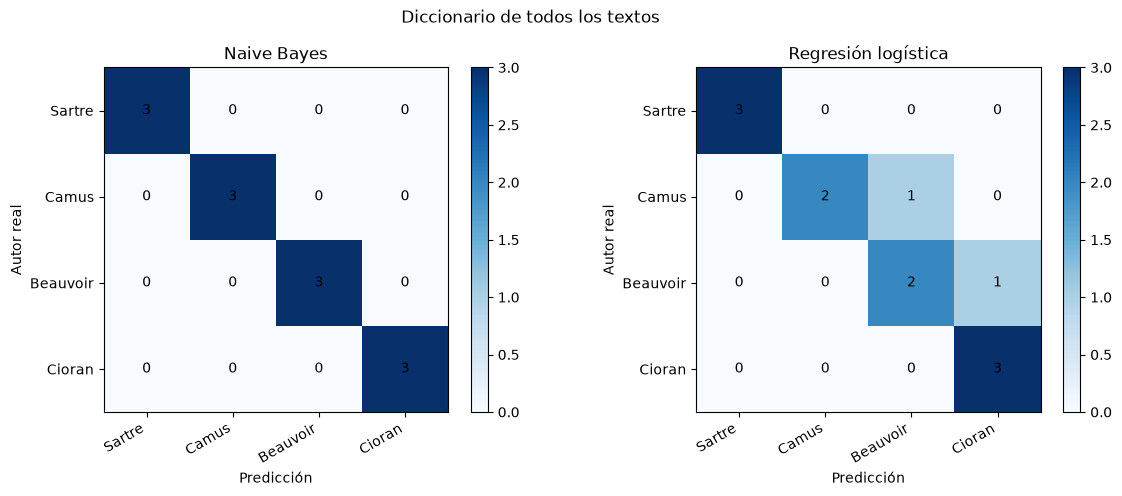

In [5]:
resultado_global = evaluate(works, vocab_global, "todos los textos")
display(resultado_global["summary"])
print("Naive Bayes")
print(resultado_global["reports"]["nb"])
print("Regresión logística")
print(resultado_global["reports"]["lr"])
display(resultado_global["detail"])
plot_matrices(resultado_global["matrices"], "Diccionario de todos los textos")


## 9. Comparación: diccionario solo de entrenamiento

Mismo preprocesamiento, mismos modelos y la misma partición.
Cambia únicamente de dónde salen las 300 palabras: aquí solo de las partes de entrenamiento.


Diccionario de entrenamiento: 300 palabras.
Palabras del diccionario global que no están en el de entrenamiento: 39.
absolu, art, avons, but, ceci, certaine, choisir, choisit, choix, constitue, créateur, création, depuis, divine, déclare, désir, ensemble, forme, grande, humanisme, ibid, jeune, lieu, maistre, mauvaise, pourquoi, pouvoir, projet, puisque, quelle, quelque, saints, sait, situation, subjectivité, travers, vrai, yeux, œuvre


,modelo,diccionario,accuracy,f1_macro
0,Multinomial Naive Bayes,todos los textos,1.000000,1.000000
1,Regresión logística,todos los textos,0.833333,0.830952
2,Multinomial Naive Bayes,solo entrenamiento,1.000000,1.000000
3,Regresión logística,solo entrenamiento,0.833333,0.830952


,autor real,parte,Naive Bayes,acierto NB,regresión logística,acierto RL
0,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 6,Jean-Paul Sartre,True,Jean-Paul Sartre,True
1,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 7,Jean-Paul Sartre,True,Jean-Paul Sartre,True
2,Jean-Paul Sartre,L'existentialisme est un humanisme — parte 8,Jean-Paul Sartre,True,Jean-Paul Sartre,True
3,Albert Camus,Le Mythe de Sisyphe — parte 6,Albert Camus,True,Albert Camus,True
4,Albert Camus,Le Mythe de Sisyphe — parte 7,Albert Camus,True,Simone de Beauvoir,False
5,Albert Camus,Le Mythe de Sisyphe — parte 8,Albert Camus,True,Albert Camus,True
6,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 6",Simone de Beauvoir,True,Simone de Beauvoir,True
7,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 7",Simone de Beauvoir,True,Simone de Beauvoir,True
8,Simone de Beauvoir,"Le Deuxième Sexe, I — parte 8",Simone de Beauvoir,True,Emil Cioran,False
9,Emil Cioran,De l'absurde à l'absolu — parte 6,Emil Cioran,True,Emil Cioran,True


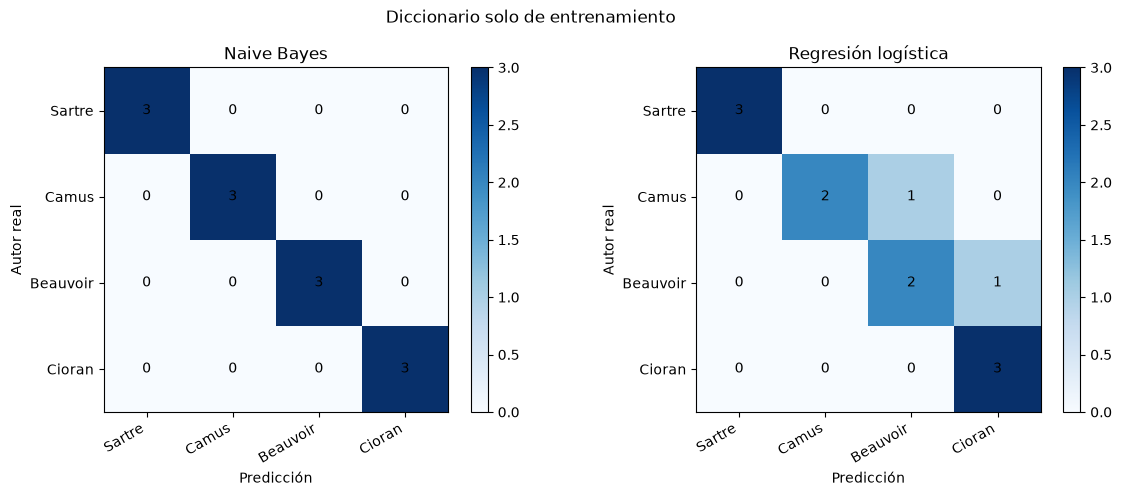

In [6]:
train_works = [work for work in works if work["particion"] == "entrenamiento"]
vocab_train, tabla_train = build_vocab(train_works)
solo_en_prueba = sorted(set(vocab_global) - set(vocab_train))
print(f"Diccionario de entrenamiento: {len(vocab_train)} palabras.")
print(f"Palabras del diccionario global que no están en el de entrenamiento: {len(solo_en_prueba)}.")
if solo_en_prueba:
    print(", ".join(solo_en_prueba))

resultado_train = evaluate(works, vocab_train, "solo entrenamiento")
comparacion = pd.concat(
    [resultado_global["summary"], resultado_train["summary"]],
    ignore_index=True,
)
display(comparacion)
display(resultado_train["detail"])
plot_matrices(resultado_train["matrices"], "Diccionario solo de entrenamiento")


## 10. Palabras que separan a los autores

Para cada autor se compara la frecuencia relativa media en sus partes de entrenamiento
con la media del resto de autores. La tabla muestra las palabras del diccionario global
con mayor diferencia a favor de ese autor. Sirven para explicar el resultado, no como un análisis literario completo.


In [7]:
def distinctive_words(relative_train: np.ndarray, y_train: np.ndarray, vocab: list[str], k: int = 8) -> pd.DataFrame:
    frames = []
    for label in LABELS:
        mask = y_train == label
        mean_in = relative_train[mask].mean(axis=0)
        mean_out = relative_train[~mask].mean(axis=0)
        delta = mean_in - mean_out
        order = np.argsort(delta)[-k:][::-1]
        frames.append(
            pd.DataFrame(
                {
                    "autor": label,
                    "palabra": [vocab[index] for index in order],
                    "diferencia": delta[order],
                }
            )
        )
    return pd.concat(frames, ignore_index=True)


palabras = distinctive_words(
    resultado_global["relative_train"],
    resultado_global["y_train"],
    resultado_global["vocab"],
)
display(palabras.round({"diferencia": 5}))


,autor,palabra,diferencia
0,Jean-Paul Sartre,que,0.01086
1,Jean-Paul Sartre,nous,0.00789
2,Jean-Paul Sartre,je,0.00742
3,Jean-Paul Sartre,qu,0.00687
4,Jean-Paul Sartre,un,0.00673
5,Jean-Paul Sartre,il,0.00659
6,Jean-Paul Sartre,homme,0.00622
7,Jean-Paul Sartre,qui,0.00459
8,Albert Camus,absurde,0.00487
9,Albert Camus,je,0.00334
